# Sleep Staging — Exploración Inicial del Dataset

**Objetivo:** Entender la estructura del dataset antes de cualquier preprocesamiento o modelado.  
**Librería principal:** MNE-Python (estándar en neurociencias para señales EEG/PSG).  
**Formato de datos:** EDF (European Data Format), estándar médico para señales fisiológicas.

---
> **Preguntas a responder:**  
> - ¿Cuántos sujetos y cuántos archivos hay?  
> - ¿Todos los archivos tienen los mismos canales y sampling rate?  
> - ¿Las clases están balanceadas?  
> - ¿Hay archivos corruptos o problemáticos?

## 0. Configuración e importaciones

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import mne

# Silenciar warnings menores de MNE (filtros distintos entre canales es normal en PSG)
mne.set_log_level('WARNING')
warnings.filterwarnings('ignore', category=RuntimeWarning)

# Rutas del proyecto — ajustar según tu estructura
DATA_PATH    = "../data/recordings"   # Archivos .edf
LABELS_PATH  = "../data/recordings"   # Archivos _sleepscoring.txt (mismo directorio aquí)

# Colores por stage — convenio AASM estándar
STAGE_COLORS = {
    'Sleep stage W':  '#e74c3c',
    'Sleep stage N1': '#f39c12',
    'Sleep stage N2': '#3498db',
    'Sleep stage N3': '#2c3e50',
    'Sleep stage R':  '#27ae60',
}

print("MNE version:", mne.__version__)

MNE version: 1.12.0


---
## 1. Inventario de archivos

Analizar qué tenemos.  
Vamos a separar archivos EDF de señales vs. archivos de anotaciones (`_sleepscoring.txt`).

In [2]:
all_files = sorted(os.listdir(DATA_PATH))

# Separar señales de anotaciones
edf_signals = [f for f in all_files if f.endswith('.edf') and 'sleepscoring' not in f]   # contiene las señales
edf_annots  = [f for f in all_files if f.endswith('.edf') and 'sleepscoring' in f]       # contiene las anotaciones (stages)
txt_labels  = [f for f in all_files if f.endswith('.txt')]                               # contiene los labels/etiquetas (stages en formato texto)

print(f"Archivos EDF (señales):      {len(edf_signals)}")
print(f"Archivos EDF (anotaciones):  {len(edf_annots)}")
print(f"Archivos TXT (labels):       {len(txt_labels)}")
print()

# Extraer IDs de sujetos
subject_ids = [f.replace('.edf', '') for f in edf_signals]
print("Primeros 10 sujetos:", subject_ids[:10])
print()

# Verificar que todo sujeto tiene su archivo de labels
missing_labels = [sid for sid in subject_ids
                  if f"{sid}_sleepscoring.txt" not in txt_labels]
if missing_labels:
    print(f"⚠️  Sujetos SIN archivo de labels ({len(missing_labels)}): {missing_labels[:5]}")
else:
    print("✅ Todos los sujetos tienen archivo de labels.")

Archivos EDF (señales):      151
Archivos EDF (anotaciones):  151
Archivos TXT (labels):       151

Primeros 10 sujetos: ['SN001', 'SN002', 'SN003', 'SN004', 'SN005', 'SN006', 'SN007', 'SN008', 'SN009', 'SN010']

✅ Todos los sujetos tienen archivo de labels.


---
## 2. Leer un archivo EDF — inspección

Usamos `preload=False` para leer solo los metadatos sin cargar toda la señal en la memoria.  

### Introducción a MNE y a la estructura de los archivos EDF

## ¿Qué es MNE?

**MNE-Python** es una librería de Python de código abierto diseñada para explorar, visualizar y analizar señales neurofisiológicas y biomédicas, como EEG, MEG, EOG, ECG y EMG.

En este proyecto se utiliza principalmente para trabajar con archivos **EDF** (*European Data Format*), un formato frecuente para almacenar registros biomédicos.

Un archivo EDF puede contener:

* señales registradas a lo largo del tiempo;
* nombres de los canales;
* frecuencia de muestreo;
* unidades físicas;
* duración de la grabación;
* información temporal;
* anotaciones, según el tipo de archivo.

Por lo tanto, un EDF no guarda solamente valores numéricos: también incluye información descriptiva sobre la medición.

---

## El módulo `mne.io`

Dentro de MNE, el módulo:

```python
mne.io
```

agrupa las funciones utilizadas para leer y escribir señales provenientes de diferentes formatos.

Como los archivos del dataset tienen extensión `.edf`, se utiliza:

```python
raw = mne.io.read_raw_edf(sample_path, preload=False)
```

Esta función lee el archivo EDF y crea un objeto llamado `raw`.

El objeto `raw` representa una **grabación continua**: contiene información sobre las señales, sus canales y sus metadatos. Además, permite acceder a los valores numéricos de las señales cuando sea necesario.

---

## ¿Qué significa `preload=False`?

El parámetro:

```python
preload=False
```

indica que MNE no debe cargar inmediatamente todas las muestras de la señal en la memoria RAM.

Esto resulta útil durante la exploración inicial porque los registros pueden ser extensos. MNE lee primero la información necesaria del archivo y carga los datos numéricos solamente cuando se solicitan.

---

## El objeto `raw`

`raw` es un objeto de MNE que representa los datos continuos de una grabación.

Puede pensarse de forma similar a un `DataFrame` de pandas:

* un `DataFrame` tiene atributos como `columns`, `shape` y métodos como `head()`;
* un objeto `raw` tiene atributos como `ch_names`, `n_times`, `times`, `info` y métodos como `get_channel_types()`.

Algunos atributos importantes son:

| Atributo            | Descripción                                                   |
| ------------------- | ------------------------------------------------------------- |
| `raw.ch_names`      | Lista con los nombres de los canales                          |
| `raw.info`          | Estructura que contiene metadatos de la grabación             |
| `raw.info["sfreq"]` | Frecuencia de muestreo en Hz                                  |
| `raw.n_times`       | Cantidad total de muestras temporales                         |
| `raw.times`         | Array con el instante temporal correspondiente a cada muestra |
| `raw.duration`      | Duración total de la grabación en segundos                    |

---

## Nombres de los canales: `raw.ch_names`

```python
raw.ch_names
```

devuelve una lista con los nombres de los canales presentes en el archivo.

Ejemplo:

```python
[
    "EEG F4-M1",
    "EEG C4-M1",
    "EEG O2-M1",
    "EEG C3-M2",
    "EMG chin",
    "EOG E1-M2",
    "EOG E2-M2",
    "ECG"
]
```

---

## Metadatos: `raw.info`

```python
raw.info
```

contiene información descriptiva sobre la grabación. Se comporta de forma similar a un diccionario de Python.

Por ejemplo:

```python
raw.info["sfreq"]
```

devuelve la frecuencia de muestreo.

Si el valor obtenido es:

```python
256.0
```

significa que se registraron **256 muestras por segundo** para cada canal.

Por ejemplo:

| Duración    | Cantidad de muestras |
| ----------- | -------------------: |
| 1 segundo   |                  256 |
| 30 segundos |                 7680 |
| 1 minuto    |               15 360 |

---

## Cantidad de muestras: `raw.n_times`

```python
raw.n_times
```

indica cuántas muestras temporales tiene la grabación completa.

Por ejemplo:

```python
raw.n_times
# 6_566_400
```

significa que cada canal contiene 6 566 400 valores.

La duración aproximada de la grabación puede calcularse como:

```python
duration_seconds = raw.n_times / raw.info["sfreq"]
```

---

## Vector temporal: `raw.times`

```python
raw.times
```

es un array que indica el instante temporal asociado con cada muestra, expresado en segundos.

Para una frecuencia de muestreo de `256 Hz`, los primeros valores serán aproximadamente:

```python
[
    0.000000,
    0.003906,
    0.007812,
    0.011719,
    ...
]
```

La separación temporal entre dos muestras es:

```python
1 / 256  # 0.00390625 segundos
```

Para acceder al instante correspondiente a la última muestra se utiliza:

```python
raw.times[-1]
```

En Python, el índice `-1` representa el último elemento de una lista o array.

También puede obtenerse la duración directamente mediante:

```python
raw.duration
```

---

## Mostrar información básica de una grabación

El siguiente código imprime un resumen del archivo analizado:

```python
print(f"Archivo:             {sample_file}")
print(f"Canales ({len(raw.ch_names)}):      {raw.ch_names}")
print(f"Frecuencia muestreo: {raw.info['sfreq']} Hz")
print(f"Duración:            {raw.duration / 3600:.2f} horas")
print(f"Total de muestras:   {raw.n_times:,}")
```

El resultado permite verificar rápidamente:

* qué archivo se está analizando;
* cuántos canales contiene;
* cómo se llaman los canales;
* cuál es la frecuencia de muestreo;
* cuánto dura la grabación;
* cuántas muestras contiene.

---

## Atributos/Metadatos

Los valores:

```python
raw.ch_names
raw.info["sfreq"]
raw.n_times
raw.times
```

son **atributos** o **metadatos** de la grabación.

**NO** son *features* que se utilizarán para entrenar un modelo de machine learning.

Más adelante, las features podrían ser variables calculadas a partir de las señales, como:

* potencia en la banda delta;
* potencia en la banda theta;
* potencia en la banda alpha;
* media de amplitud;
* desviación estándar;
* entropía;
* indicadores de artefactos.

---

## Tipos de canal

Cada canal tiene un tipo asociado. Algunos ejemplos son:

| Tipo  | Significado                  |
| ----- | ---------------------------- |
| `eeg` | Actividad eléctrica cerebral |
| `eog` | Movimientos oculares         |
| `emg` | Actividad muscular           |
| `ecg` | Actividad cardíaca           |

MNE permite consultar los tipos registrados con:

```python
raw.get_channel_types()
```

---

## Importante: consultar un tipo no significa detectarlo correctamente

El método:

```python
raw.get_channel_types()
```

no analiza la forma de la señal para descubrir si se trata de EEG, ECG, EOG o EMG.

Solamente devuelve los tipos que MNE tiene asignados en ese momento.

Al leer un EDF, MNE puede asumir inicialmente que ciertos canales son de tipo `eeg`. Por ese motivo, canales como:

```text
EMG chin
EOG E1-M2
ECG
```

podrían aparecer incorrectamente clasificados como:

```text
eeg
```

---

## Posibilidad: Asignación manual recomendada

Como los canales del dataset son conocidos, puede definirse un diccionario:

```python
channel_types = {
    "EEG F4-M1": "eeg",
    "EEG C4-M1": "eeg",
    "EEG O2-M1": "eeg",
    "EEG C3-M2": "eeg",
    "EMG chin":   "emg",
    "EOG E1-M2":  "eog",
    "EOG E2-M2":  "eog",
    "ECG":        "ecg",
}
```

Luego, los tipos correctos se pueden asignar mediante:

```python
raw.set_channel_types(channel_types)
```

Finalmente, pueden verificarse con:

```python
print("Tipos de canal:")
for ch, channel_type in zip(raw.ch_names, raw.get_channel_types()):
    print(f"  {ch:<20} → {channel_type}")
```

La salida esperada es:

```text
EEG F4-M1            → eeg
EEG C4-M1            → eeg
EEG O2-M1            → eeg
EEG C3-M2            → eeg
EMG chin             → emg
EOG E1-M2            → eog
EOG E2-M2            → eog
ECG                  → ecg
```

---

## Cómo explorar un objeto desconocido

No es necesario memorizar todos los atributos y métodos disponibles.

Para inspeccionar un objeto de Python puede utilizarse:

```python
print(type(raw))
```

Esto muestra la clase del objeto.

Para obtener un resumen:

```python
print(raw)
```

Para consultar la ayuda:

```python
help(raw)
```

Para listar atributos y métodos disponibles:

```python
dir(raw)
```

Para inspeccionar los metadatos:

```python
print(raw.info)
```

Para observar las claves disponibles dentro de `info`:

```python
print(raw.info.keys())
```

---

## Resumen conceptual

```text
Archivo EDF
    ↓
mne.io.read_raw_edf(...)
    ↓
Objeto raw
    ├── señales biomédicas continuas
    ├── nombres de canales: raw.ch_names
    ├── frecuencia de muestreo: raw.info["sfreq"]
    ├── cantidad de muestras: raw.n_times
    ├── vector temporal: raw.times
    ├── duración: raw.duration
    └── métodos para procesar e inspeccionar la señal
```

La idea principal es que `raw` no es solamente una matriz de números. Es un objeto estructurado que reúne las señales, sus metadatos y distintos métodos para trabajar con ellas.


In [8]:
# Leer el primer archivo como ejemplo representativo
sample_file = edf_signals[0]
sample_path = os.path.join(DATA_PATH, sample_file)

raw = mne.io.read_raw_edf(sample_path, preload=False)

print(raw)
print(type(raw))
dir(raw)


<RawEDF | SN001.edf, 8 x 6566400 (25650.0 s), ~11 KiB, data not loaded>
<class 'mne.io.edf.edf.RawEDF'>


['__class__',
 '__contains__',
 '__del__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__enter__',
 '__eq__',
 '__exit__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setitem__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_annotations',
 '_cals',
 '_check_bad_segment',
 '_comp',
 '_cropped_samp',
 '_dtype',
 '_dtype_',
 '_extra_attributes',
 '_filenames',
 '_first_samps',
 '_first_time',
 '_get_buffer_size',
 '_get_channel_positions',
 '_get_duration_string',
 '_getitem',
 '_handle_tmin_tmax',
 '_init_kwargs',
 '_last_samps',
 '_last_time',
 '_orig_units',
 '_parse_get_set_params',
 '_pick_drop_channels',
 '_pick_projs',
 '_preload_data',
 '_projector',
 '_raw_extras',
 '_raw_lengths',
 '_read_comp_grade',
 '_read_picks',
 

In [9]:
print(raw.info)

<Info | 8 non-empty values
 bads: []
 ch_names: EEG F4-M1, EEG C4-M1, EEG O2-M1, EEG C3-M2, EMG chin, EOG E1-M2, ...
 chs: 8 EEG
 custom_ref_applied: False
 highpass: 1.0 Hz
 lowpass: 35.0 Hz
 meas_date: 2001-01-01 23:59:30 UTC
 nchan: 8
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: SN001, sex: 0, last_name: X>
>


In [17]:
print(f"Canales: {len(raw.ch_names)}")
print(f"Canales: {raw.ch_names}")

Canales: 8
Canales: ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2', 'EMG chin', 'EOG E1-M2', 'EOG E2-M2', 'ECG']


In [10]:
print(raw.info.keys())

dict_keys(['acq_pars', 'acq_stim', 'ctf_head_t', 'description', 'dev_head_t', 'dev_ctf_t', 'dig', 'experimenter', 'utc_offset', 'device_info', 'file_id', 'highpass', 'hpi_subsystem', 'kit_system_id', 'helium_info', 'line_freq', 'lowpass', 'meas_date', 'meas_id', 'proj_id', 'proj_name', 'subject_info', 'xplotter_layout', 'gantry_angle', 'bads', 'chs', 'comps', 'events', 'hpi_meas', 'hpi_results', 'projs', 'proc_history', 'custom_ref_applied', 'sfreq', 'ch_names', 'nchan'])


In [15]:
print(f"Archivo:            {sample_file}")
print(f"Canales ({len(raw.ch_names)}):     {raw.ch_names}")
print(f"Frecuencia muestreo: {raw.info['sfreq']} Hz")
print(f"Duración:           {raw.times[-1]/3600:.2f} horas ({raw.times[-1]:.0f} seg)")
print(f"Total de muestras:  {raw.n_times:,}")
print()

# Tipos de canal detectados automáticamente por MNE
ch_types = {}

print("Tipos de canal detectados:")
for ch in raw.ch_names:
    detected_type = raw.get_channel_types([ch])[0]
    ch_types[ch] = detected_type
    print(f"  {ch}: {ch_types[ch]}")


Archivo:            SN001.edf
Canales (8):     ['EEG F4-M1', 'EEG C4-M1', 'EEG O2-M1', 'EEG C3-M2', 'EMG chin', 'EOG E1-M2', 'EOG E2-M2', 'ECG']
Frecuencia muestreo: 256.0 Hz
Duración:           7.12 horas (25650 seg)
Total de muestras:  6,566,400

Tipos de canal detectados:
  EEG F4-M1: eeg
  EEG C4-M1: eeg
  EEG O2-M1: eeg
  EEG C3-M2: eeg
  EMG chin: eeg
  EOG E1-M2: eeg
  EOG E2-M2: eeg
  ECG: eeg


---
## 3. Visualización de señales crudas

Vamos a graficar los **primeros 5 minutos** de grabación.  
Importante: normalizar por canal para poder compararlos en la misma figura (cada señal tiene escala distinta).



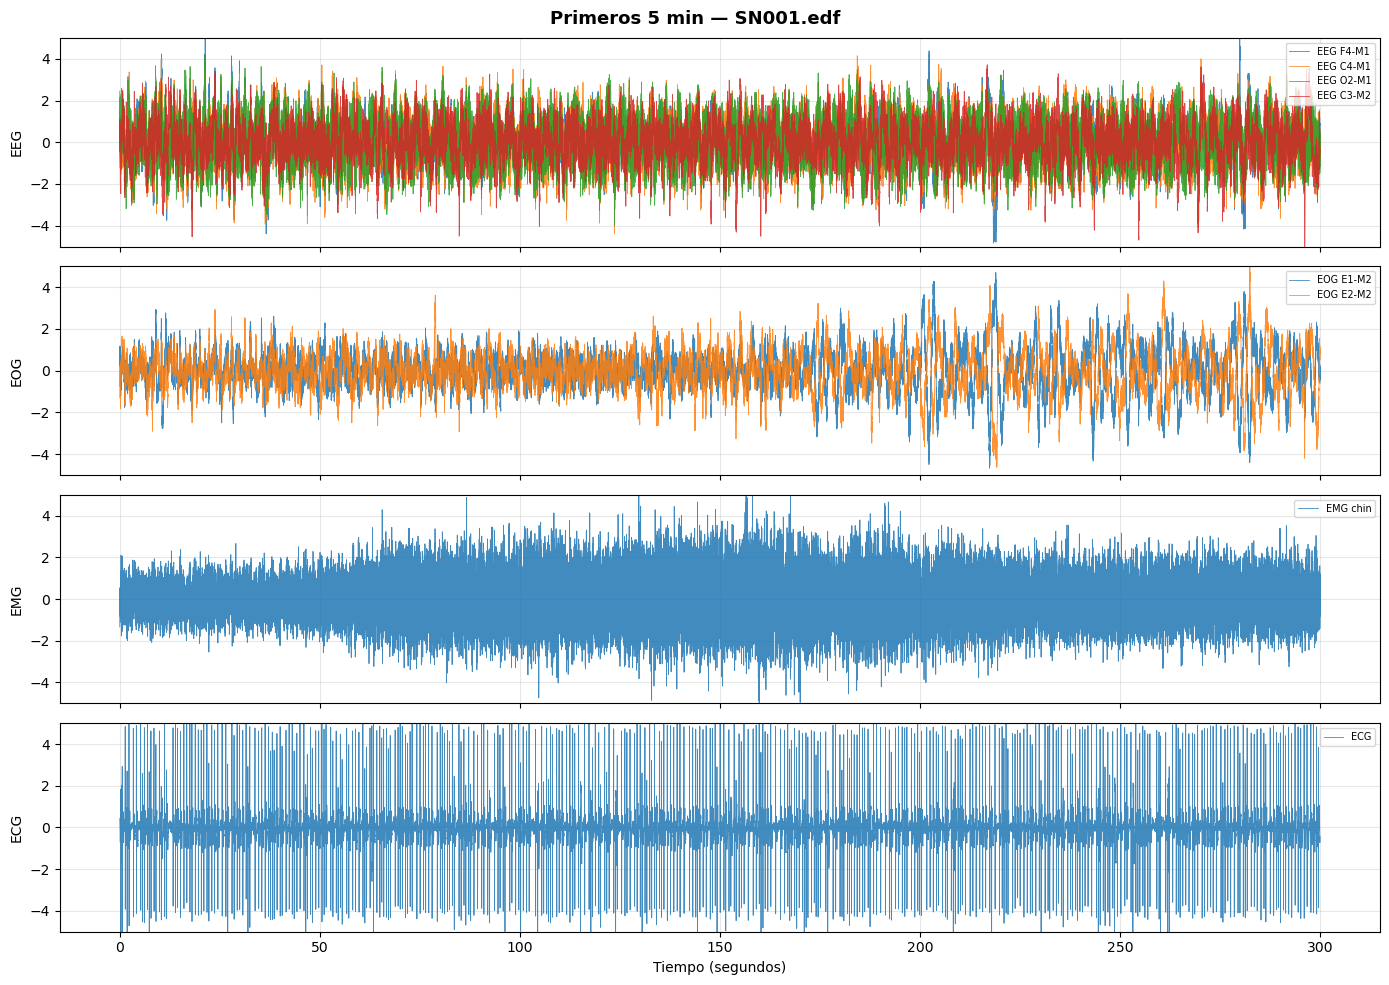

In [4]:
# Cargar solo los primeros 5 minutos para visualización rápida
raw_crop = mne.io.read_raw_edf(sample_path, preload=True)
raw_crop.crop(tmin=0, tmax=300)  # 0 a 300 segundos = 5 minutos

data, times = raw_crop.get_data(return_times=True)  # shape: (n_canales, n_muestras)

# Agrupar canales por tipo para visualizar en bloques
channel_groups = {
    'EEG': [ch for ch in raw.ch_names if ch.startswith('EEG')],
    'EOG': [ch for ch in raw.ch_names if ch.startswith('EOG')],
    'EMG': [ch for ch in raw.ch_names if ch.startswith('EMG')],
    'ECG': [ch for ch in raw.ch_names if ch.startswith('ECG')],
}

fig, axes = plt.subplots(len(channel_groups), 1, figsize=(14, 10), sharex=True)
fig.suptitle(f"Primeros 5 min — {sample_file}", fontsize=13, fontweight='bold')

for ax, (group_name, channels) in zip(axes, channel_groups.items()):
    for ch_name in channels:
        idx = raw.ch_names.index(ch_name)
        signal = data[idx]
        # Normalizar a media 0 y desvío 1 para poder superponer canales
        signal_norm = (signal - signal.mean()) / (signal.std() + 1e-10)
        ax.plot(times, signal_norm, lw=0.6, label=ch_name, alpha=0.85)
    ax.set_ylabel(group_name, fontsize=10)
    ax.legend(loc='upper right', fontsize=7)
    ax.set_ylim(-5, 5)  # rango fijo para comparar visualmente
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Tiempo (segundos)")
plt.tight_layout()
plt.show()

# Limpiar de memoria
del raw_crop

### Observaciones iniciales sobre las señales crudas

En los primeros 5 minutos del sujeto `SN001` no se observan canales completamente planos ni señales ausentes. Los cuatro canales EEG presentan actividad continua, mientras que las señales EOG muestran variaciones compatibles con movimientos oculares. La señal EMG presenta cambios en su amplitud a lo largo del tiempo, posiblemente asociados con variaciones en la actividad muscular. El ECG muestra picos repetitivos y regulares, coherentes con la actividad cardíaca.

Esta visualización permite realizar una primera verificación cualitativa de la calidad de los datos. Sin embargo, como las señales están normalizadas y se muestran 5 minutos completos, el gráfico es útil principalmente para detectar problemas evidentes. Para analizar artefactos o patrones específicos conviene observar ventanas más cortas y conservar también las amplitudes originales.


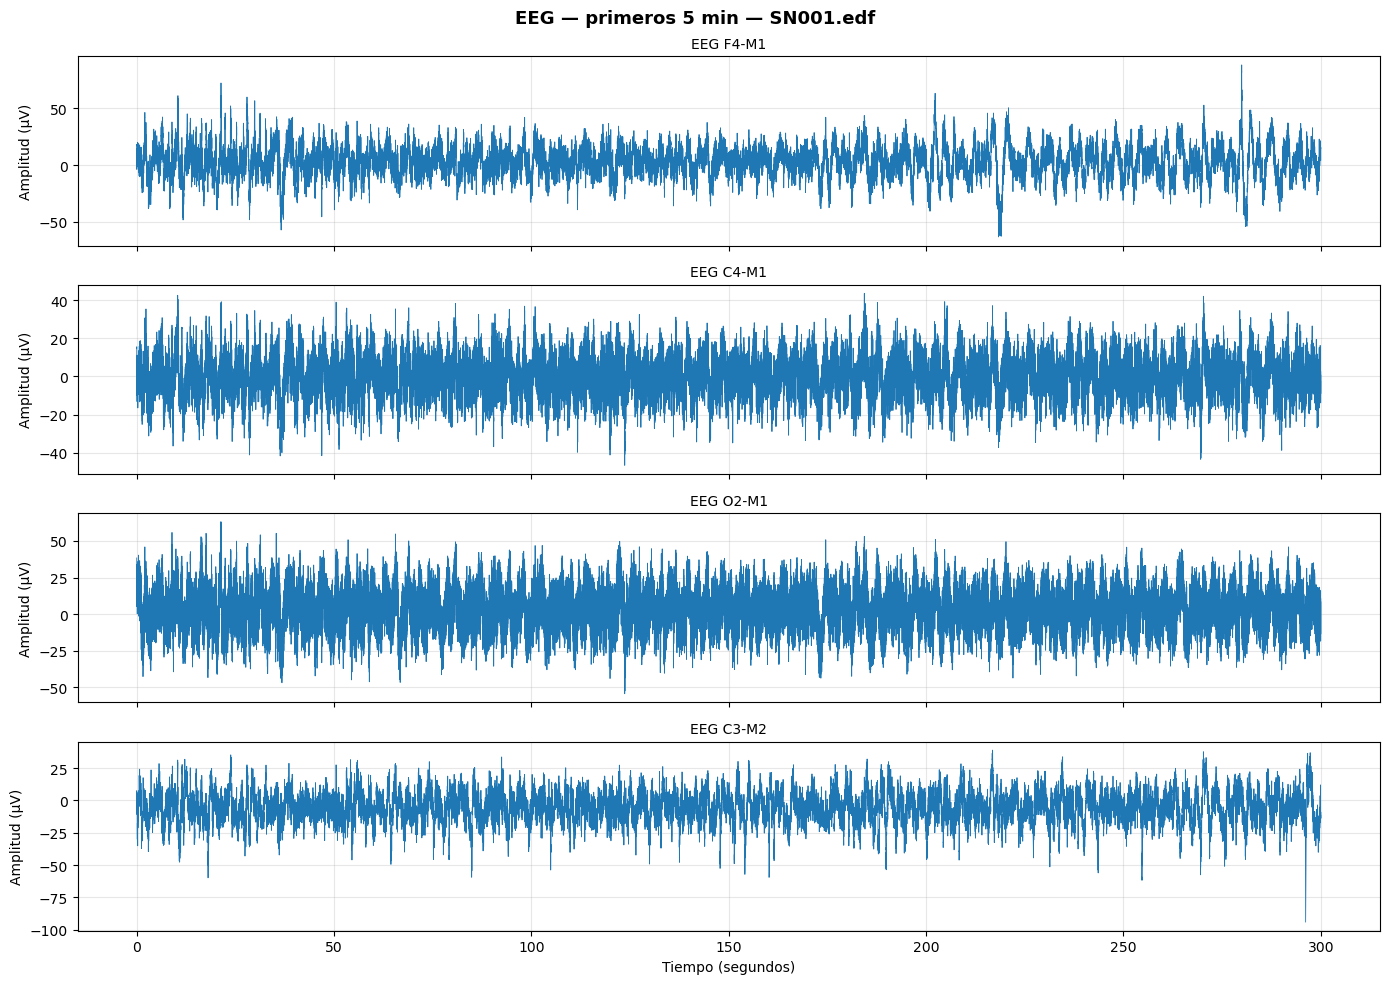

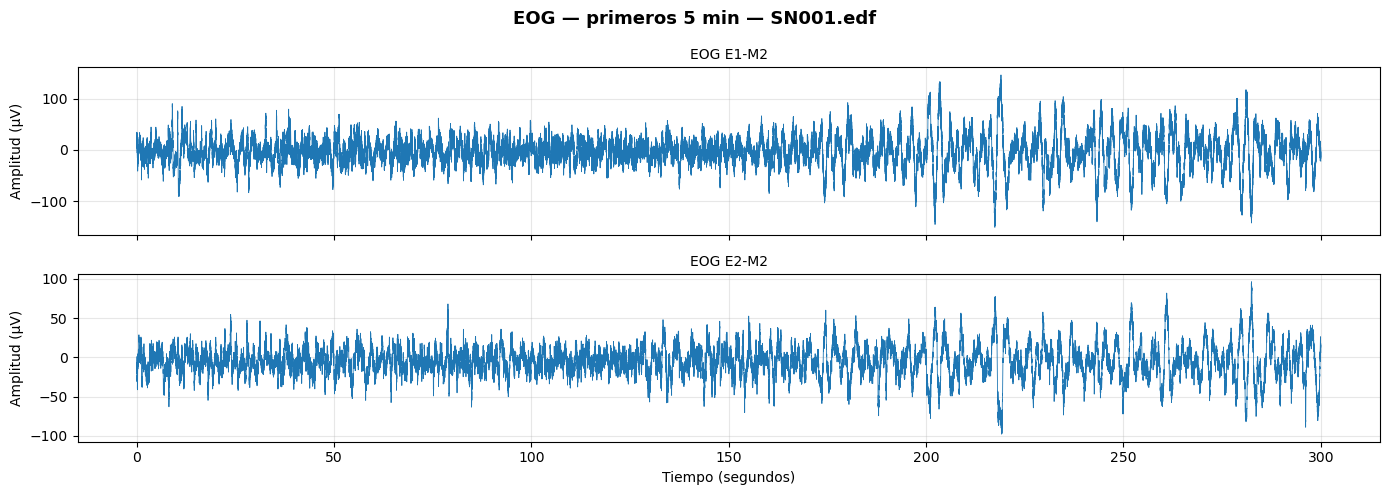

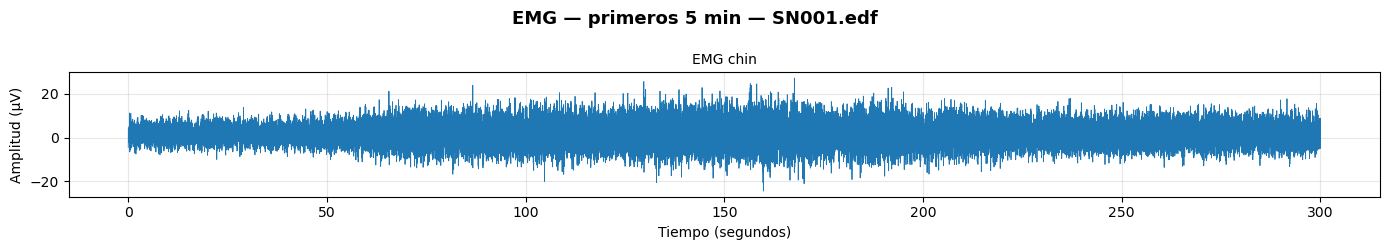

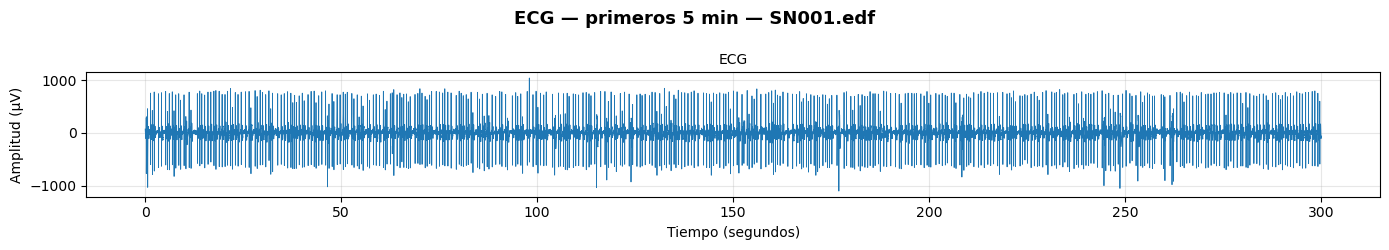

In [18]:
# ============================================================
# Visualización de señales crudas sin normalización
# ============================================================

# Cargar solamente el fragmento que se desea visualizar
raw_crop = mne.io.read_raw_edf(sample_path, preload=True)
raw_crop.crop(tmin=0, tmax=300)  # primeros 5 minutos

# Obtener señales y vector temporal
# MNE devuelve las amplitudes en voltios
data, times = raw_crop.get_data(return_times=True)

# Agrupar canales según su nombre
channel_groups = {
    "EEG": [ch for ch in raw_crop.ch_names if ch.startswith("EEG")],
    "EOG": [ch for ch in raw_crop.ch_names if ch.startswith("EOG")],
    "EMG": [ch for ch in raw_crop.ch_names if ch.startswith("EMG")],
    "ECG": [ch for ch in raw_crop.ch_names if ch.startswith("ECG")],
}

# Crear una figura independiente para cada grupo
for group_name, channels in channel_groups.items():

    if not channels:
        continue

    fig, axes = plt.subplots(
        nrows=len(channels),
        ncols=1,
        figsize=(14, 2.5 * len(channels)),
        sharex=True
    )

    # Cuando existe un único canal, matplotlib no devuelve una lista
    # Esta línea asegura que axes siempre pueda recorrerse
    axes = np.atleast_1d(axes)

    fig.suptitle(
        f"{group_name} — primeros 5 min — {sample_file}",
        fontsize=13,
        fontweight="bold"
    )

    for ax, ch_name in zip(axes, channels):

        idx = raw_crop.ch_names.index(ch_name)

        # Convertir voltios a microvoltios
        signal_uv = data[idx] * 1e6

        ax.plot(times, signal_uv, linewidth=0.6)
        ax.set_ylabel("Amplitud (µV)")
        ax.set_title(ch_name, fontsize=10)
        ax.grid(True, alpha=0.3)

    axes[-1].set_xlabel("Tiempo (segundos)")

    plt.tight_layout()
    plt.show()

# Liberar memoria
del raw_crop

---
## 4. Análisis de canales en todo el dataset

Verificamos que todos los archivos comparten los mismos canales.  
Es importante detectar inconsistencias, ya que implicaría normalizar o filtrar sujetos antes del modelado.

In [20]:
channel_info = []

for file_name in edf_signals:
    file_path = os.path.join(DATA_PATH, file_name)

    try:
        raw = mne.io.read_raw_edf(
            file_path,
            preload=False,
            verbose=False
        )

        subject_id = file_name.replace(".edf", "")

        file_info = {
            "subject": subject_id,
            "n_channels": len(raw.ch_names),
            "channels": sorted(raw.ch_names),
            "sfreq": raw.info["sfreq"],
            "duration_h": raw.duration / 3600,
        }

        channel_info.append(file_info)

    except Exception as error:
        print(f"❌ Error leyendo {file_name}: {error}")

df_info = pd.DataFrame(channel_info)

# ¿Todos tienen los mismos canales?
unique_channel_sets = df_info['channels'].apply(tuple).nunique()
print(f"Conjuntos de canales distintos en el dataset: {unique_channel_sets}")

if unique_channel_sets == 1:
    print("✅ Todos los archivos tienen exactamente los mismos canales.")
else:
    print("⚠️  Hay variación en los canales — revisar antes de modelar.")
    print(df_info['channels'].value_counts())

# ¿Todos tienen el mismo sampling rate?
print(f"\nSampling rates presentes: {df_info['sfreq'].unique()}")

print(f"\nResumen general:")
print(df_info[['n_channels', 'sfreq', 'duration_h']].describe().round(2))

Conjuntos de canales distintos en el dataset: 1
✅ Todos los archivos tienen exactamente los mismos canales.

Sampling rates presentes: [256.]

Resumen general:
       n_channels  sfreq  duration_h
count       151.0  151.0      151.00
mean          8.0  256.0        7.58
std           0.0    0.0        1.24
min           8.0  256.0        3.92
25%           8.0  256.0        6.97
50%           8.0  256.0        7.52
75%           8.0  256.0        8.39
max           8.0  256.0       10.93


---
## 5. Distribución de duraciones

Las grabaciones PSG suelen durar entre 6 y 9 horas.  
Grabaciones muy cortas pueden indicar archivos incompletos o corruptos.

Estadísticas de duración (horas):
  Mínima:   3.92 h
  Máxima:   10.93 h
  Promedio: 7.58 h
  Mediana:  7.52 h

⚠️  Grabaciones cortas (< 4.0h): 1
   subject  duration_h
60   SN062    3.917778


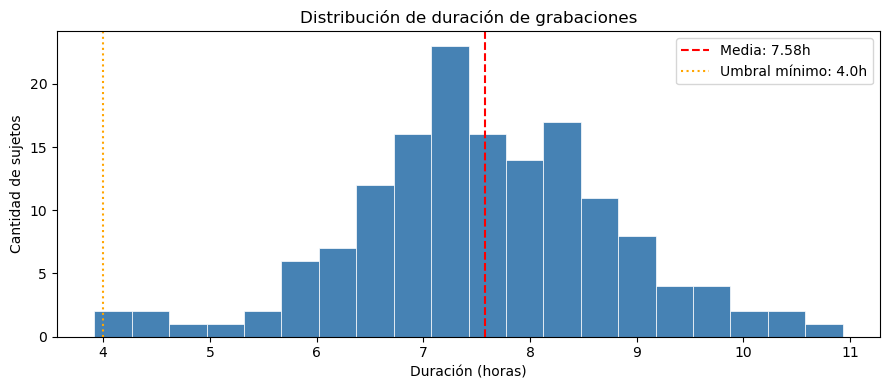

In [21]:
durations = df_info['duration_h']

print("Estadísticas de duración (horas):")
print(f"  Mínima:   {durations.min():.2f} h")
print(f"  Máxima:   {durations.max():.2f} h")
print(f"  Promedio: {durations.mean():.2f} h")
print(f"  Mediana:  {durations.median():.2f} h")

# Detectar outliers: grabaciones anormalmente cortas (< 4 horas)
SHORT_THRESHOLD = 4.0
short_recordings = df_info[durations < SHORT_THRESHOLD]
if len(short_recordings) > 0:
    print(f"\n⚠️  Grabaciones cortas (< {SHORT_THRESHOLD}h): {len(short_recordings)}")
    print(short_recordings[['subject', 'duration_h']])
else:
    print(f"\n✅ Ninguna grabación menor a {SHORT_THRESHOLD} horas.")

# Histograma
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(durations, bins=20, color='steelblue', edgecolor='white', linewidth=0.5)
ax.axvline(durations.mean(), color='red', ls='--', label=f'Media: {durations.mean():.2f}h')
ax.axvline(SHORT_THRESHOLD, color='orange', ls=':', label=f'Umbral mínimo: {SHORT_THRESHOLD}h')
ax.set_xlabel("Duración (horas)")
ax.set_ylabel("Cantidad de sujetos")
ax.set_title("Distribución de duración de grabaciones")
ax.legend()
plt.tight_layout()
plt.show()

---
## 6. Leer y explorar labels (hypnograms)

El **hypnogram** es la secuencia temporal de etapas de sueño, epoch por epoch.  
Cada epoch dura 30 segundos (estándar AASM).  
Esta será nuestra variable target en el modelado.

In [22]:
def load_hypnogram(txt_path):
    """
    Lee el archivo de anotaciones y devuelve solo los sleep stages.
    Descarta eventos puntuales (Lights off, arousals, etc.).
    """
    df = pd.read_csv(txt_path)
    df.columns = df.columns.str.strip()  # limpiar espacios innecesarios en nombres de columnas
    df['Annotation'] = df['Annotation'].str.strip() # limpiar espacios en anotaciones
    # Quedarse solo con epochs de 30s (los sleep stages)
    # Se crea una mascara booleana para filtrar solo las filas donde 'Annotation' comienza con 'Sleep stage'
    stages = df[df['Annotation'].str.startswith('Sleep stage')].copy()
    stages = stages.reset_index(drop=True) # reiniciar índices después de filtrar
    return stages

# Leer labels del sujeto de ejemplo
sample_labels_path = os.path.join(LABELS_PATH, sample_file.replace('.edf', '_sleepscoring.txt'))
labels_df = load_hypnogram(sample_labels_path)

print(f"Epochs totales: {len(labels_df)}")
print(f"Duración cubierta: {len(labels_df) * 30 / 3600:.2f} horas")
print()
print("Distribución de stages:")
print(labels_df['Annotation'].value_counts())
print()
print("Primeras filas:")
display(labels_df.head(10))

Epochs totales: 854
Duración cubierta: 7.12 horas

Distribución de stages:
Annotation
Sleep stage N2    430
Sleep stage W     151
Sleep stage R     141
Sleep stage N1    109
Sleep stage N3     23
Name: count, dtype: int64

Primeras filas:


,Date,Time,Recording onset,Duration,Annotation,Linked channel
0,01.01.01,23.59.30,0.0,30,Sleep stage W,
1,02.01.01,00.00.00,30.0,30,Sleep stage W,
2,02.01.01,00.00.30,60.0,30,Sleep stage W,
3,02.01.01,00.01.00,90.0,30,Sleep stage W,
4,02.01.01,00.01.30,120.0,30,Sleep stage W,
5,02.01.01,00.02.00,150.0,30,Sleep stage W,
6,02.01.01,00.02.30,180.0,30,Sleep stage W,
7,02.01.01,00.03.00,210.0,30,Sleep stage W,
8,02.01.01,00.03.30,240.0,30,Sleep stage N1,
9,02.01.01,00.04.00,270.0,30,Sleep stage N1,


In [23]:
print(labels_df['Linked channel'].value_counts())

Linked channel
    854
Name: count, dtype: int64


### 6.1 Hypnogram visual

El hypnogram muestra la arquitectura del sueño: esperamos ver ciclos de ~90 minutos  
con descenso progresivo hacia N2/N3 al inicio y más REM hacia el final de la noche.

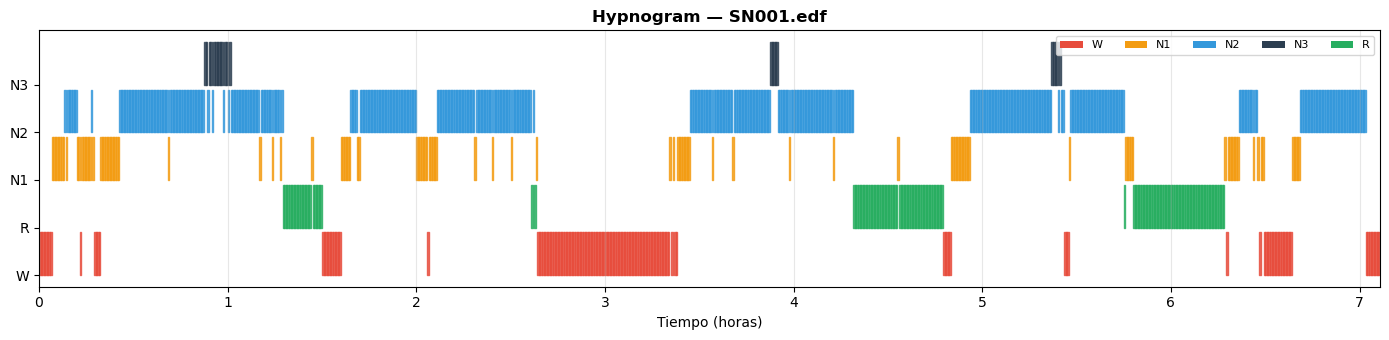

In [24]:
# Mapa stage → valor numérico para plotear (orden clínico estándar)
STAGE_ORDER = {
    'Sleep stage W':  0,
    'Sleep stage R':  1,
    'Sleep stage N1': 2,
    'Sleep stage N2': 3,
    'Sleep stage N3': 4,
}
STAGE_LABELS = {}

for stage_name, stage_number in STAGE_ORDER.items():
    short_name = stage_name.replace("Sleep stage ", "")
    STAGE_LABELS[stage_number] = short_name

labels_df['stage_num'] = labels_df['Annotation'].map(STAGE_ORDER)
time_hours = np.arange(len(labels_df)) * 30 / 3600  # convertir epoch index a horas

fig, ax = plt.subplots(figsize=(14, 3.5))

# Colorear por stage
for i, row in labels_df.iterrows():
    color = STAGE_COLORS.get(row['Annotation'], 'gray')
    ax.fill_between([time_hours[i], time_hours[i] + 30/3600],
                    row['stage_num'], row['stage_num'] + 0.9,
                    color=color, alpha=0.8)

ax.set_yticks(list(STAGE_LABELS.keys()))
ax.set_yticklabels(list(STAGE_LABELS.values()), fontsize=10)
ax.set_xlabel("Tiempo (horas)")
ax.set_title(f"Hypnogram — {sample_file}", fontweight='bold')
ax.set_xlim(0, time_hours[-1])
ax.grid(True, axis='x', alpha=0.3)

# Leyenda
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=k.replace('Sleep stage ', ''))
                   for k, c in STAGE_COLORS.items() if k in labels_df['Annotation'].values]
ax.legend(handles=legend_elements, loc='upper right', fontsize=8, ncol=5)
plt.tight_layout()
plt.show()

---
## 7. Distribución de clases — todo el dataset

El **desbalance de clases** es uno de los problemas más importantes en sleep staging.  
N2 suele dominar (~50%), mientras que N1 y N3 son minoritarios.  
Si no lo manejamos, el modelo tenderá a predecir siempre N2.

In [ ]:
all_stages = []  # Acumular stages de todos los sujetos

for name in edf_signals:
    txt_path = os.path.join(LABELS_PATH, name.replace('.edf', '_sleepscoring.txt'))
    if not os.path.exists(txt_path):
        continue
    try:
        df_subj = load_hypnogram(txt_path)
        # Agregar stages a la lista global
        all_stages.extend(df_subj['Annotation'].tolist())
    except Exception as e:
        print(f"  ❌ Error leyendo {name}: {e}")

# Conteos globales
stage_counts = pd.Series(all_stages).value_counts()
stage_pct    = (stage_counts / stage_counts.sum() * 100).round(1)

print("Distribución global de sleep stages:")
print(pd.DataFrame({'Epochs': stage_counts, 'Porcentaje': stage_pct}))
print(f"\nTotal epochs: {len(all_stages):,}")
print(f"Horas totales anotadas: {len(all_stages) * 30 / 3600:.1f} h")

# Calcular ratio de desbalance (clase mayoritaria / clase minoritaria)
ratio = stage_counts.max() / stage_counts.min()
print(f"\nRatio de desbalance (max/min): {ratio:.1f}x")
if ratio > 10:
    print("⚠️  Desbalance severo — considerar oversampling, class weights o métricas balanceadas.")
elif ratio > 4:
    print("⚠️  Desbalance moderado — tener en cuenta en la estrategia de evaluación.")
else:
    print("✅ Desbalance aceptable.")

Distribución global de sleep stages:
                Epochs  Porcentaje
Sleep stage N2   50083        36.5
Sleep stage N3   26671        19.4
Sleep stage W    23686        17.3
Sleep stage R    21255        15.5
Sleep stage N1   15548        11.3

Total epochs: 137,243
Horas totales anotadas: 1143.7 h

Ratio de desbalance (max/min): 3.2x
✅ Desbalance aceptable.


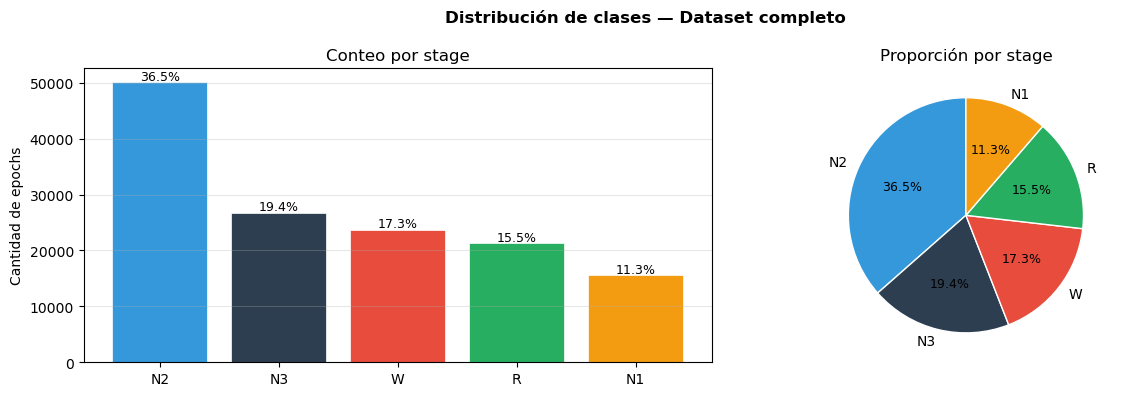

In [10]:
# Visualización del desbalance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Distribución de clases — Dataset completo", fontweight='bold')

colors = [STAGE_COLORS.get(s, 'gray') for s in stage_counts.index]
short_labels = [s.replace('Sleep stage ', '') for s in stage_counts.index]

# Barplot de conteos
ax1.bar(short_labels, stage_counts.values, color=colors, edgecolor='white', linewidth=0.5)
for i, (cnt, pct) in enumerate(zip(stage_counts.values, stage_pct.values)):
    ax1.text(i, cnt + stage_counts.max()*0.01, f'{pct}%', ha='center', fontsize=9)
ax1.set_ylabel("Cantidad de epochs")
ax1.set_title("Conteo por stage")
ax1.grid(True, axis='y', alpha=0.3)

# Pie chart
wedges, texts, autotexts = ax2.pie(
    stage_counts.values, labels=short_labels,
    colors=colors, autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=1)
)
for at in autotexts:
    at.set_fontsize(9)
ax2.set_title("Proporción por stage")

plt.tight_layout()
plt.show()

---
## 8. Estadísticas de señal por canal

Analizamos amplitud, media y varianza de cada canal.  


In [29]:
# Cargar señal del sujeto de ejemplo (completa)
raw_full = mne.io.read_raw_edf(sample_path, preload=True, verbose=False)
# Obtener todas las señales en formato numpy (shape: n_canales x n_muestras)
data_all, _ = raw_full.get_data(return_times=True)

# Estadísticas por canal
stats_rows = []
for i, ch_name in enumerate(raw_full.ch_names):
    sig = data_all[i]
    stats_rows.append({
        'Canal':      ch_name,
        'Media (µV)': sig.mean() * 1e6,
        'Std (µV)':   sig.std() * 1e6,
        'Min (µV)':   sig.min() * 1e6,
        'Max (µV)':   sig.max() * 1e6,
        'Rango (µV)': (sig.max() - sig.min()) * 1e6,
        '% NaN':      np.isnan(sig).mean() * 100,
        '% plano':    (np.diff(sig) == 0).mean() * 100,  # % de muestras sin cambio
    })

df_stats = pd.DataFrame(stats_rows).set_index('Canal').round(3)
display(df_stats)

# Alertas automáticas
print()
if df_stats['% NaN'].max() > 0:
    print("⚠️  Hay valores NaN en algún canal.")
else:
    print("✅ No hay valores NaN.")

flat_channels = df_stats[df_stats['% plano'] > 20].index.tolist()
if flat_channels:
    print(f"⚠️  Canales con muchos segmentos planos (>20%): {flat_channels}")
else:
    print("✅ Ningún canal tiene segmentos planos excesivos.")

,Media (µV),Std (µV),Min (µV),Max (µV),Rango (µV),% NaN,% plano
Canal,,,,,,,
EEG F4-M1,3.706,39.765,-800.000,800.000,1600.000,0.0,0.354
EEG C4-M1,0.079,39.324,-800.000,800.000,1600.000,0.0,0.175
EEG O2-M1,3.248,29.999,-800.000,800.000,1600.000,0.0,0.215
EEG C3-M2,-5.548,47.948,-800.000,800.000,1600.000,0.0,0.263
EMG chin,1.611,4.777,-402.191,345.501,747.692,0.0,0.369
EOG E1-M2,-3.181,46.648,-800.000,800.000,1600.000,0.0,0.320
EOG E2-M2,-4.836,46.175,-800.000,800.000,1600.000,0.0,0.337
ECG,7.439,122.414,-2400.000,2400.000,4800.000,0.0,0.349



✅ No hay valores NaN.
✅ Ningún canal tiene segmentos planos excesivos.


---
## 9. Power Spectral Density (PSD)

El PSD muestra cómo se distribuye la energía de la señal en frecuencias.  
Las bandas de interés en sleep staging son:

| Banda | Rango | Relevancia |
|-------|-------|------------|
| Delta | 0.5–4 Hz | N3 (sueño profundo) |
| Theta | 4–8 Hz | N1, REM |
| Alpha | 8–13 Hz | W (relajado con ojos cerrados) |
| Sigma | 12–15 Hz | N2 (sleep spindles) |
| Beta | 15–30 Hz | W (activo) |

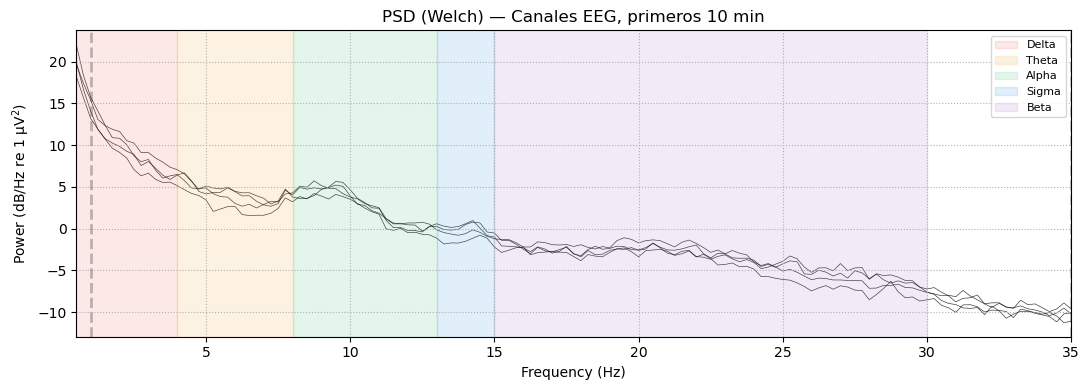

In [27]:
raw_full = mne.io.read_raw_edf(sample_path, preload=True, verbose=False)

eeg_channels = [
    ch for ch in raw_full.ch_names
    if ch.startswith("EEG")
]

# PSD con método Welch (estándar para señales EEG)
# Usamos solo los primeros 10 minutos para que sea rápido
raw_psd = raw_full.copy().crop(tmin=0, tmax=600)

# Calcular PSD solo para canales EEG
spectrum = raw_psd.compute_psd(
    method='welch',
    fmin=0.5, fmax=35,     # rango clínicamente relevante
    n_fft=1024,
    picks=eeg_channels
)

fig, ax = plt.subplots(figsize=(11, 4))
spectrum.plot(axes=ax, show=False)
ax.set_title("PSD (Welch) — Canales EEG, primeros 10 min")

# Marcar bandas de frecuencia
freq_bands = [
    (0.5, 4,   'Delta', '#e74c3c', 0.12),
    (4,   8,   'Theta', '#f39c12', 0.12),
    (8,   13,  'Alpha', '#27ae60', 0.12),
    (13,  15,  'Sigma', '#3498db', 0.15),
    (15,  30,  'Beta',  '#9b59b6', 0.12),
]
ylim = ax.get_ylim()
for fmin_b, fmax_b, label, color, alpha in freq_bands:
    ax.axvspan(fmin_b, fmax_b, alpha=alpha, color=color, label=label)

ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

del raw_psd

### Análisis espectral de señales EEG mediante PSD

## ¿Qué es la PSD?

La **Power Spectral Density** o **PSD** (*densidad espectral de potencia*) permite analizar cómo se distribuye la potencia de una señal entre distintas frecuencias.

Hasta este punto, las señales se visualizaron en el dominio temporal:

```text
amplitud vs. tiempo
```

Con la PSD, se estudian en el dominio frecuencial:

```text
potencia vs. frecuencia
```

Esto permite responder preguntas como:

* ¿En qué frecuencias se concentra principalmente la energía de la señal?
* ¿Predominan las componentes lentas o rápidas?
* ¿Existen diferencias entre los canales EEG?
* ¿Se observan bandas frecuenciales asociadas con etapas del sueño?

---

## ¿Por qué es importante en sleep staging?

Las etapas del sueño están relacionadas con distintos patrones de actividad cerebral.

Algunas bandas frecuenciales relevantes son:

| Banda | Rango aproximado | Asociación frecuente                   |
| ----- | ---------------: | -------------------------------------- |
| Delta |         0.5–4 Hz | sueño profundo, especialmente N3       |
| Theta |           4–8 Hz | sueño ligero y REM                     |
| Alpha |          8–13 Hz | vigilia relajada                       |
| Sigma |         13–15 Hz | *sleep spindles*, frecuentes en N2     |
| Beta  |         15–30 Hz | actividad rápida, frecuente en vigilia |

Por este motivo, el análisis espectral de EEG resulta útil para diferenciar etapas del sueño.

---

## ¿Por qué se calcula primero solo para EEG?

El dataset contiene distintos tipos de señales:

* EEG: actividad eléctrica cerebral;
* EOG: movimientos oculares;
* EMG: actividad muscular;
* ECG: actividad cardíaca.

Todas pueden analizarse en frecuencia, pero cada una tiene escalas e interpretaciones fisiológicas diferentes.

En esta sección se calcula la PSD únicamente para EEG porque las bandas delta, theta, alpha, sigma y beta se interpretan principalmente sobre actividad cerebral.

Más adelante podrían analizarse EOG, EMG o ECG por separado, utilizando rangos frecuenciales adecuados para cada señal.

---

## Selección de un fragmento de señal

Para realizar una exploración rápida se utilizan solamente los primeros 10 minutos del sujeto:

```python
raw_psd = raw_full.copy().crop(tmin=0, tmax=600)
```

donde:

```text
600 segundos = 10 minutos
```

El método:

```python
.copy()
```

crea una copia del objeto original antes de recortarlo.

Esto evita modificar accidentalmente la grabación completa almacenada en:

```python
raw_full
```

---

## Cálculo de PSD con el método de Welch

La PSD se calcula mediante:

```python
spectrum = raw_psd.compute_psd(
    method="welch",
    fmin=0.5,
    fmax=35,
    n_fft=1024,
    picks=eeg_channels
)
```

El método de Welch funciona conceptualmente de la siguiente forma:

```text
señal completa
    ↓
dividir en ventanas temporales
    ↓
calcular FFT de cada ventana
    ↓
obtener la potencia por frecuencia
    ↓
promediar los resultados
    ↓
PSD más estable
```

A diferencia de calcular una única FFT sobre toda la señal, Welch promedia varios espectros.

Esto permite obtener una curva más estable y menos sensible a ruido, movimientos o eventos aislados.

---

## Significado de los parámetros

### `method="welch"`

Indica que se utiliza el método de Welch para estimar la PSD.

---

### `fmin=0.5`

Define la frecuencia mínima analizada:

```text
0.5 Hz
```

---

### `fmax=35`

Define la frecuencia máxima analizada:

```text
35 Hz
```

Este rango incluye las bandas más relevantes para una primera exploración de EEG de sueño:

```text
Delta, Theta, Alpha, Sigma y Beta
```

---

### `n_fft=1024`

Indica cuántos puntos se utilizan para calcular cada FFT.

Como la frecuencia de muestreo es:

```text
256 Hz
```

la resolución frecuencial aproximada es:

```text
256 / 1024 = 0.25 Hz
```

Esto significa que el espectro se evalúa aproximadamente cada:

```text
0.25 Hz
```

---

### `picks=eeg_channels`

Indica qué canales deben utilizarse para calcular la PSD.

En este caso:

```python
eeg_channels = [
    "EEG F4-M1",
    "EEG C4-M1",
    "EEG O2-M1",
    "EEG C3-M2"
]
```

Por lo tanto, el espectro se calcula solamente para los cuatro canales EEG.

---

## ¿Qué contiene `spectrum`?

La variable:

```python
spectrum
```

contiene un objeto generado por MNE con:

* frecuencias analizadas;
* valores de PSD;
* canales utilizados;
* metadatos asociados;
* métodos para graficar el resultado.

El gráfico se genera con:

```python
spectrum.plot()
```

---

## ¿Cómo interpretar el gráfico?

En el gráfico final:

```text
eje X → frecuencia en Hz
eje Y → densidad espectral de potencia
```

Cada curva representa un canal EEG.

El gráfico permite observar:

* qué frecuencias predominan;
* si la potencia se concentra principalmente en bajas frecuencias;
* si existen diferencias entre canales;
* si aparecen picos particulares;
* si los valores parecen coherentes con actividad EEG.

---

## Limitación de esta visualización

La PSD calculada en esta sección utiliza los primeros 10 minutos completos del registro.

Durante ese período podrían existir distintas etapas del sueño:

```text
W, N1, N2, N3 o R
```

Por lo tanto, esta visualización muestra un resumen espectral general, pero no permite comparar etapas directamente.

Para analizar diferencias entre clases, más adelante será necesario:

```text
dividir la señal en epochs de 30 segundos
    ↓
asociar cada epoch con su etiqueta
    ↓
calcular PSD por epoch
    ↓
comparar PSD promedio por sleep stage
```

---

## Resumen conceptual

```text
grabación EEG
    ↓
seleccionar primeros 10 minutos
    ↓
quedarse solo con canales EEG
    ↓
calcular PSD con Welch
    ↓
analizar potencia por frecuencia
    ↓
interpretar bandas relevantes para sleep staging
```

La PSD permite pasar de una inspección visual de la señal en el tiempo a un análisis más útil para estudiar patrones frecuenciales relacionados con las etapas del sueño.


---
## 10. PSD comparado por sleep stage

La firma espectral de cada stage es distinta y será la base del feature engineering.  
Esperamos ver delta dominante en N3, spindles (12-15Hz) en N2, theta en REM.

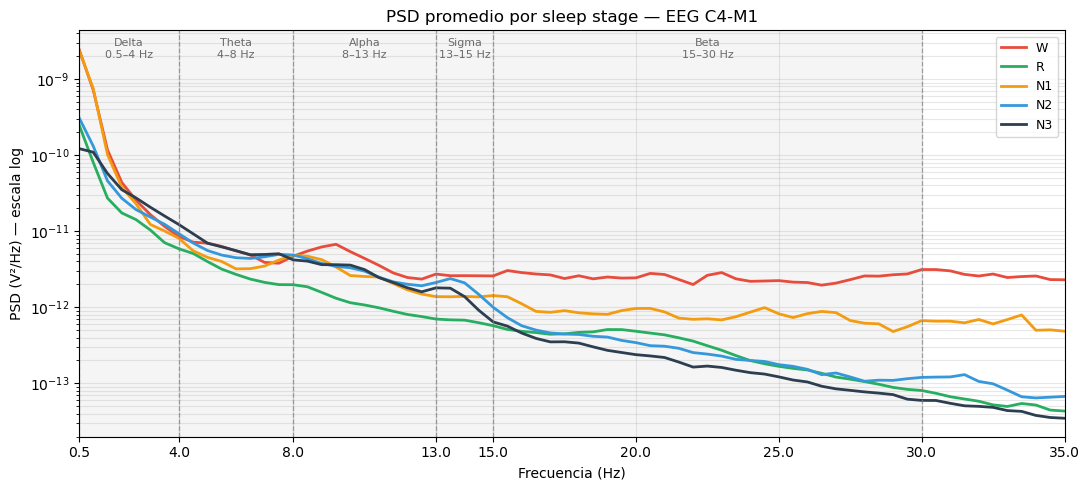

In [34]:
from scipy.signal import welch

# Usar un canal EEG central (C4-M1 es el estándar AASM)
eeg_channel = 'EEG C4-M1'
ch_idx = raw_full.ch_names.index(eeg_channel)
sfreq = raw_full.info['sfreq']
epoch_samples = int(30 * sfreq)  # 30 segundos × 256 Hz = 7680 muestras por epoch

# Alinear labels y señal
labels_df_aligned = load_hypnogram(sample_labels_path)
# Asegurar que el número de epochs no exceda lo que la señal puede cubrir
n_epochs = min(len(labels_df_aligned), raw_full.n_times // epoch_samples)

# Calcular PSD promedio por stage
psd_by_stage = {stage: [] for stage in STAGE_ORDER.keys()}
freqs = None

for i in range(n_epochs):
    stage = labels_df_aligned.iloc[i]['Annotation']   # buscar el stage correspondiente al epoch actual
    if stage not in psd_by_stage: 
        continue                        # ignorar stages no reconocidos
    # Extraer el fragmento de señal correspondiente a este epoch
    # El índice i corresponde al epoch i-ésimo, que comienza en i*epoch_samples y termina en (i+1)*epoch_samples
    start = i * epoch_samples
    end   = start + epoch_samples
    epoch_signal = data_all[ch_idx, start:end]
    # Calcular PSD con Welch para el fragmento especificado
    f, pxx = welch(epoch_signal, fs=sfreq, nperseg=512)
    # Guardar frecuencias (solo la primera vez, asumiendo que no cambian entre epochs)
    if freqs is None:
        freqs = f
    # Filtrar hasta 35 Hz
    mask = f <= 35
    psd_by_stage[stage].append(pxx[mask])

freqs_plot = freqs[freqs <= 35]

# Plot
fig, ax = plt.subplots(figsize=(11, 5))
# Para cada stage, calcular la media y desviación estándar de las PSDs y plotear con sombreado
for stage, psds in psd_by_stage.items():
    if len(psds) == 0:
        continue
    mean_psd = np.mean(psds, axis=0)
    std_psd  = np.std(psds, axis=0)
    lower_bound = np.maximum(mean_psd - std_psd, 1e-20)
    upper_bound = mean_psd + std_psd
    color = STAGE_COLORS.get(stage, 'gray')
    label = stage.replace('Sleep stage ', '')
    ax.semilogy(freqs_plot, mean_psd, color=color, lw=2, label=label)

# Marcar bandas de frecuencia con fondo gris
freq_bands = [
    (0.5, 4,  "Delta"),
    (4,   8,  "Theta"),
    (8,   13, "Alpha"),
    (13,  15, "Sigma"),
    (15,  30, "Beta"),
]

# Límites de todas las bandas
band_limits = [0.5, 4, 8, 13, 15, 30]

for fmin_b, fmax_b, band_name in freq_bands:

    ax.axvspan(
        fmin_b,
        fmax_b,
        color="gray",
        alpha=0.08
    )

    ax.text(
        (fmin_b + fmax_b) / 2,
        0.98,
        f"{band_name}\n{fmin_b:g}–{fmax_b:g} Hz",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=8,
        color="dimgray"
    )

# Líneas verticales en los límites
for limit in band_limits:
    ax.axvline(
        limit,
        color="gray",
        linestyle="--",
        linewidth=0.9,
        alpha=0.7
    )


ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("PSD (V²/Hz) — escala log")
ax.set_title(f"PSD promedio por sleep stage — {eeg_channel}")
ax.legend(fontsize=9)
ax.set_xlim(0.5, 35)
# Mostrar explícitamente los límites en el eje X
ax.set_xticks([0.5, 4, 8, 13, 15, 20, 25, 30, 35])
ax.grid(True, which='both', alpha=0.3)


plt.tight_layout()
plt.show()

### PSD promedio por etapa de sueño

En esta sección se utilizó el canal EEG central `EEG C4-M1` y se dividió la señal en epochs de 30 segundos. Para cada epoch se calculó la PSD mediante el método de Welch y luego se agruparon los resultados según la etapa de sueño (`W`, `R`, `N1`, `N2` y `N3`).

Finalmente, se graficó la PSD promedio de cada etapa y se marcaron las bandas frecuenciales principales:

* **Delta:** 0.5–4 Hz
* **Theta:** 4–8 Hz
* **Alpha:** 8–13 Hz
* **Sigma:** 13–15 Hz
* **Beta:** 15–30 Hz

Como observación inicial, se aprecia que `N3` presenta mayor potencia relativa en frecuencias bajas, mientras que `W` conserva mayor potencia en frecuencias medias y altas. Las diferencias entre etapas no son perfectamente separables, pero muestran que el contenido frecuencial del EEG varía según el sleep stage.


---
## 11. Calidad de señal — detección de problemas

Antes de modelar, necesitamos identificar epochs problemáticos.  
Criterios comunes:
- **Amplitud extrema:** pico > 500 µV puede considerarse artefacto (movimiento, electrodo suelto)
- **Segmento plano:** señal constante por > 1 segundo = electrodo desconectado
- **Varianza muy baja:** canal prácticamente muerto

In [36]:
AMPLITUDE_THRESHOLD_UV = 500   # µV — umbral clínico estándar para EEG
FLAT_DURATION_S = 1.0          # segundos de señal plana = artefacto
flat_samples = int(FLAT_DURATION_S * sfreq) # Cantidad de muestras para considerar un segmento plano

bad_epochs = []  # Guardar índices de epochs problemáticos

for i in range(n_epochs):
    start = i * epoch_samples
    end   = start + epoch_samples
    reasons = []

    for ch_idx_q, ch_name in enumerate(raw_full.ch_names):
        if not ch_name.startswith('EEG'): # solo evaluar canales EEG para artefactos de amplitud y flatness:
            continue
        seg = data_all[ch_idx_q, start:end] * 1e6  # a µV

        # Amplitud extrema
        if np.abs(seg).max() > AMPLITUDE_THRESHOLD_UV:
            reasons.append(f"amplitud>{AMPLITUDE_THRESHOLD_UV}µV en {ch_name}")

        # Segmento plano: buscar runs de valores idénticos
        diffs = np.diff(seg)
        # Encontrar la longitud máxima de segmentos planos (donde la diferencia es 0)
        consecutive_flat = np.max(np.diff(np.where(np.concatenate(([True], diffs != 0, [True])))[0]))
        if consecutive_flat > flat_samples:
            reasons.append(f"segmento plano en {ch_name}")

    if reasons:
        # Obtener el stage correspondiente a este epoch para el reporte
        stage = labels_df_aligned.iloc[i]['Annotation'] if i < len(labels_df_aligned) else 'N/A'
        # Guardar el índice del epoch, el stage y las razones por las cuales se considera problemático
        bad_epochs.append({'epoch': i, 'stage': stage, 'razones': ', '.join(set(reasons))})

df_bad = pd.DataFrame(bad_epochs)
pct_bad = len(df_bad) / n_epochs * 100

print(f"Epochs problemáticos: {len(df_bad)} / {n_epochs} ({pct_bad:.1f}%)")

if len(df_bad) > 0:
    print("\nDistribución de epochs malos por stage:")
    print(df_bad['stage'].value_counts())
    print("\nEjemplos:")
    display(df_bad.head(10))

if pct_bad > 20:
    print("⚠️  Más del 20% de epochs problemáticos — revisar calidad de datos.")
elif pct_bad > 5:
    print("⚠️  Entre 5-20% de epochs con posibles artefactos — aplicar rechazo de artefactos.")
else:
    print("✅ Calidad de señal aceptable.")

Epochs problemáticos: 53 / 854 (6.2%)

Distribución de epochs malos por stage:
stage
Sleep stage W     24
Sleep stage N1    14
Sleep stage N2     9
Sleep stage R      6
Name: count, dtype: int64

Ejemplos:


,epoch,stage,razones
0,26,Sleep stage W,amplitud>500µV en EEG O2-M1
1,34,Sleep stage N1,amplitud>500µV en EEG O2-M1
2,35,Sleep stage W,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."
3,44,Sleep stage N1,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."
4,53,Sleep stage N2,amplitud>500µV en EEG C3-M2
5,81,Sleep stage N2,amplitud>500µV en EEG C3-M2
6,87,Sleep stage N2,amplitud>500µV en EEG C3-M2
7,173,Sleep stage N1,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."
8,179,Sleep stage R,amplitud>500µV en EEG F4-M1
9,180,Sleep stage W,"amplitud>500µV en EEG F4-M1, amplitud>500µV en..."


⚠️  Entre 5-20% de epochs con posibles artefactos — aplicar rechazo de artefactos.


### Análisis global de calidad por sujeto

Hasta este punto, la detección preliminar de artefactos se aplicó únicamente al sujeto de ejemplo. En esta sección se repite el análisis para todos los sujetos del dataset.

Para cada archivo se calcula:

* duración de la grabación;
* cantidad de canales;
* frecuencia de muestreo;
* cantidad de labels disponibles;
* cantidad de epochs completos presentes en la señal;
* diferencia entre epochs de señal y labels;
* cantidad y porcentaje de epochs EEG potencialmente problemáticos.

Un epoch se marca como sospechoso si al menos un canal EEG presenta una amplitud absoluta superior a `500 µV` o permanece exactamente plano durante al menos un segundo.

Este análisis es exploratorio: los epochs detectados no se eliminan automáticamente. El objetivo es identificar sujetos o segmentos que requieran una revisión más detallada durante el preprocesamiento.


In [37]:
import gc

# ============================================================
# Análisis global de calidad de señal por sujeto
# ============================================================

def has_flat_segment(signal, min_samples):
    """
    Devuelve True si existe un tramo de al menos min_samples
    muestras consecutivas con exactamente el mismo valor.
    """

    if len(signal) < min_samples:
        return False

    # True cuando dos muestras consecutivas tienen el mismo valor
    repeated_values = np.diff(signal) == 0

    # Detectar la longitud de cada secuencia de valores repetidos
    boundaries = np.concatenate(([True], ~repeated_values, [True]))
    run_lengths = np.diff(np.flatnonzero(boundaries))

    return run_lengths.max() >= min_samples


# Una fila de resumen por sujeto
subject_summary = []

# Información detallada de cada epoch sospechoso
all_bad_epochs = []


for file_name in edf_signals:

    subject_id = file_name.replace(".edf", "")
    file_path = os.path.join(DATA_PATH, file_name)

    labels_file = file_name.replace(".edf", "_sleepscoring.txt")
    labels_path = os.path.join(LABELS_PATH, labels_file)

    try:
        # Leer metadatos del EDF sin cargar inicialmente toda la señal
        raw_subject = mne.io.read_raw_edf(
            file_path,
            preload=False,
            verbose=False
        )

        # Parámetros propios del sujeto
        sfreq_subject = raw_subject.info["sfreq"]
        samples_per_epoch = int(30 * sfreq_subject)
        flat_samples = int(FLAT_DURATION_S * sfreq_subject)

        # Identificar canales EEG por nombre
        eeg_channels_subject = [
            ch for ch in raw_subject.ch_names
            if ch.startswith("EEG")
        ]

        # Calcular cuántos epochs completos entran en la señal
        signal_epochs = raw_subject.n_times // samples_per_epoch

        # Leer labels si existen
        if os.path.exists(labels_path):
            labels_subject = load_hypnogram(labels_path)
            n_labels = len(labels_subject)
        else:
            labels_subject = None
            n_labels = 0

        # Analizar solamente epochs que tengan señal y label
        epochs_to_check = min(signal_epochs, n_labels)

        # Cargar únicamente los canales EEG
        eeg_data = raw_subject.get_data(
            picks=eeg_channels_subject
        )

        bad_epochs_subject = 0

        for epoch_idx in range(epochs_to_check):

            start = epoch_idx * samples_per_epoch
            end = start + samples_per_epoch

            reasons = []

            # Revisar cada canal EEG
            for eeg_idx, channel_name in enumerate(eeg_channels_subject):

                # Extraer epoch y convertir amplitud de V a µV
                segment_uv = eeg_data[eeg_idx, start:end] * 1e6

                # Regla 1: amplitud extrema
                if np.abs(segment_uv).max() > AMPLITUDE_THRESHOLD_UV:
                    reasons.append(
                        f"amplitud>{AMPLITUDE_THRESHOLD_UV}µV en {channel_name}"
                    )

                # Regla 2: segmento plano
                if has_flat_segment(segment_uv, flat_samples):
                    reasons.append(
                        f"segmento plano en {channel_name}"
                    )

            # Guardar epoch si se detectó al menos un problema
            if reasons:
                bad_epochs_subject += 1

                all_bad_epochs.append({
                    "subject": subject_id,
                    "epoch": epoch_idx,
                    "stage": labels_subject.iloc[epoch_idx]["Annotation"],
                    "reasons": ", ".join(sorted(set(reasons)))
                })

        # Porcentaje de epochs sospechosos del sujeto
        if epochs_to_check > 0:
            pct_bad = bad_epochs_subject / epochs_to_check * 100
        else:
            pct_bad = np.nan

        # Guardar resumen del sujeto
        subject_summary.append({
            "subject": subject_id,
            "duration_h": raw_subject.duration / 3600,
            "n_channels": len(raw_subject.ch_names),
            "sfreq": sfreq_subject,
            "n_labels": n_labels,
            "signal_epochs": signal_epochs,
            "difference": signal_epochs - n_labels,
            "epochs_checked": epochs_to_check,
            "bad_epochs": bad_epochs_subject,
            "pct_bad": pct_bad
        })

        # Liberar memoria antes de procesar el siguiente sujeto
        del raw_subject, eeg_data
        gc.collect()

    except Exception as error:
        print(f"❌ Error procesando {file_name}: {error}")


# Convertir resultados a DataFrames
df_subject_summary = pd.DataFrame(subject_summary)
df_all_bad_epochs = pd.DataFrame(all_bad_epochs)

# Redondear columnas para mejorar visualización
df_subject_summary["duration_h"] = df_subject_summary["duration_h"].round(2)
df_subject_summary["pct_bad"] = df_subject_summary["pct_bad"].round(1)

print(f"Sujetos procesados: {len(df_subject_summary)}")
print(f"Epochs sospechosos totales: {len(df_all_bad_epochs)}")

display(df_subject_summary.head())

Sujetos procesados: 151
Epochs sospechosos totales: 11610


,subject,duration_h,n_channels,sfreq,n_labels,signal_epochs,difference,epochs_checked,bad_epochs,pct_bad
0,SN001,7.12,8,256.0,854,855,1,854,53,6.2
1,SN002,7.14,8,256.0,856,856,0,856,35,4.1
2,SN003,7.95,8,256.0,954,954,0,954,77,8.1
3,SN004,8.47,8,256.0,1016,1016,0,1016,13,1.3
4,SN005,8.00,8,256.0,959,959,0,959,110,11.5


In [38]:
# Sujetos con mayor porcentaje de epochs sospechosos
df_subject_summary_sorted = (
    df_subject_summary
    .sort_values("pct_bad", ascending=False)
    .reset_index(drop=True)
)

display(df_subject_summary_sorted.head(15))

,subject,duration_h,n_channels,sfreq,n_labels,signal_epochs,difference,epochs_checked,bad_epochs,pct_bad
0,SN032,9.90,8,256.0,1188,1188,0,1188,1134,95.5
1,SN033,4.35,8,256.0,522,522,0,522,423,81.0
2,SN020,7.90,8,256.0,948,948,0,948,400,42.2
3,SN133,8.29,8,256.0,995,995,0,995,328,33.0
4,SN049,6.68,8,256.0,801,801,0,801,256,32.0
5,SN018,7.18,8,256.0,862,862,0,862,234,27.1
6,SN072,8.82,8,256.0,1058,1058,0,1058,218,20.6
7,SN079,9.31,8,256.0,1117,1117,0,1117,222,19.9
8,SN115,7.14,8,256.0,857,857,0,857,157,18.3
9,SN125,10.02,8,256.0,1202,1202,0,1202,219,18.2


In [39]:
# Sujetos con más del 20% de epochs sospechosos
subjects_to_review = df_subject_summary[
    df_subject_summary["pct_bad"] > 20
]

print(f"Sujetos con más del 20% de epochs sospechosos: {len(subjects_to_review)}")

display(subjects_to_review)

Sujetos con más del 20% de epochs sospechosos: 7


,subject,duration_h,n_channels,sfreq,n_labels,signal_epochs,difference,epochs_checked,bad_epochs,pct_bad
16,SN018,7.18,8,256.0,862,862,0,862,234,27.1
18,SN020,7.90,8,256.0,948,948,0,948,400,42.2
30,SN032,9.90,8,256.0,1188,1188,0,1188,1134,95.5
31,SN033,4.35,8,256.0,522,522,0,522,423,81.0
47,SN049,6.68,8,256.0,801,801,0,801,256,32.0
69,SN072,8.82,8,256.0,1058,1058,0,1058,218,20.6
130,SN133,8.29,8,256.0,995,995,0,995,328,33.0


---
## 12. Spectrograma por stage — visualización final

El spectrograma muestra cómo evoluciona el contenido frecuencial en el tiempo.  
Es una de las visualizaciones más informativas en análisis de sueño.

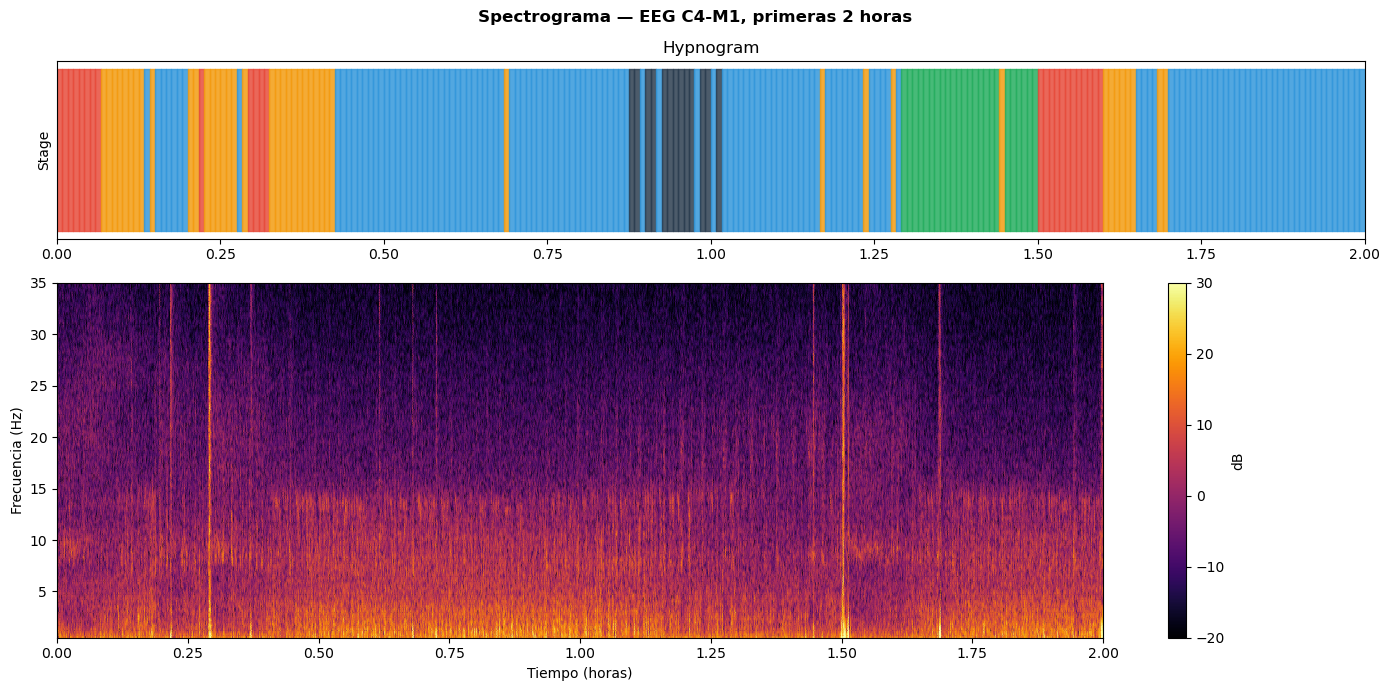

In [ ]:
from scipy.signal import spectrogram as scipy_spectrogram

# Tomar 2 horas de señal EEG para el spectrograma
TWO_HOURS = int(2 * 3600 * sfreq)
# Extraer el canal EEG C4-M1 (estándar AASM) y convertir a µV
signal_2h = data_all[raw_full.ch_names.index('EEG C4-M1'), :TWO_HOURS] * 1e6  # µV

# f_spec: vector de frecuencias, t_spec: vector de tiempos, Sxx: matriz de potencias (frecuencia x tiempo)
# Parámetros de ventana: 4 segundos con 50% de overlap para buen balance entre resolución temporal y frecuencia
f_spec, t_spec, Sxx = scipy_spectrogram(
    signal_2h, fs=sfreq,
    nperseg=int(4 * sfreq),   # ventana de 4 segundos
    noverlap=int(2 * sfreq),  # 50% overlap
    scaling='density'
)

# Limitar a 0.5–35 Hz
freq_mask = (f_spec >= 0.5) & (f_spec <= 35)
f_plot = f_spec[freq_mask]
Sxx_plot = Sxx[freq_mask, :]

fig, (ax_hyp, ax_spec) = plt.subplots(2, 1, figsize=(14, 7),
                                       gridspec_kw={'height_ratios': [1, 2]})
fig.suptitle(f"Spectrograma — EEG C4-M1, primeras 2 horas", fontweight='bold')

# Hypnogram encima (solo primeras 2 horas)
n_epochs_2h = int(2 * 3600 / 30)  # 240 epochs
labels_2h = labels_df_aligned.iloc[:min(n_epochs_2h, len(labels_df_aligned))]
time_h_2h = np.arange(len(labels_2h)) * 30 / 3600

for i, row in labels_2h.iterrows():
    color = STAGE_COLORS.get(row['Annotation'], 'gray')
    ax_hyp.fill_between([time_h_2h[i], time_h_2h[i] + 30/3600], 0, 1,
                         color=color, alpha=0.85)
ax_hyp.set_yticks([])
ax_hyp.set_xlim(0, 2)
ax_hyp.set_ylabel("Stage")
ax_hyp.set_title("Hypnogram")

# Spectrograma
t_h = t_spec / 3600  # convertir a horas
im = ax_spec.pcolormesh(t_h, f_plot, 10 * np.log10(Sxx_plot + 1e-30),
                         cmap='inferno', shading='gouraud', vmin=-20, vmax=30)
plt.colorbar(im, ax=ax_spec, label='dB')
ax_spec.set_ylabel("Frecuencia (Hz)")
ax_spec.set_xlabel("Tiempo (horas)")
ax_spec.set_xlim(0, 2)
ax_spec.set_ylim(0.5, 35)

plt.tight_layout()
plt.show()

### Spectrograma EEG y evolución temporal de las etapas de sueño

En esta sección se analizaron las primeras 2 horas del canal `EEG C4-M1`. La señal se dividió en ventanas de 4 segundos con un solapamiento del 50%, y para cada ventana se calculó la potencia espectral. El resultado se representa mediante un spectrograma:

* eje X: tiempo en horas;
* eje Y: frecuencia en Hz;
* color: potencia de la señal en dB.

En la parte superior se muestra el hypnogram correspondiente al mismo intervalo, donde cada color representa una etapa de sueño distinta.

Como observación inicial, la mayor parte de la potencia se concentra en frecuencias bajas, especialmente por debajo de 10 Hz, lo cual es esperable en señales EEG de sueño. También se observan cambios en el contenido frecuencial a medida que varían las etapas del sueño y algunos eventos verticales de mayor intensidad, que podrían corresponder a transiciones, movimientos o posibles artefactos. Esta visualización permite relacionar la evolución temporal de las etapas con cambios en la actividad espectral del EEG.


---
## 13. Resumen — checklist antes de avanzar

Antes de pasar a preprocesamiento o modelado, verificar:

In [17]:
print("=" * 55)
print("  CHECKLIST PRE-MODELADO")
print("=" * 55)

checks = [
    ("Todos los sujetos tienen labels",        len(missing_labels) == 0),
    ("Canales consistentes entre sujetos",     unique_channel_sets == 1),
    ("Mismo sampling rate en todos",           df_info['sfreq'].nunique() == 1),
    ("No hay valores NaN",                     df_stats['% NaN'].max() == 0),
    ("Epochs malos < 20%",                     pct_bad < 20),
]

for label, ok in checks:
    icon = "✅" if ok else "❌"
    print(f"  {icon}  {label}")

print()
print("Próximos pasos recomendados:")
print("  1. Filtrado de señal (bandpass 0.5–35 Hz)")
print("  2. Rechazo de artefactos (ICA o umbral de amplitud)")
print("  3. Segmentación en epochs de 30s alineados con labels")
print("  4. Extracción de features espectrales por banda")
print("  5. Estrategia para clase desbalanceada (class weights / SMOTE)")
print("  6. Split sujeto-independiente (no mezclar sujetos entre train/test)")

  CHECKLIST PRE-MODELADO
  ✅  Todos los sujetos tienen labels
  ✅  Canales consistentes entre sujetos
  ✅  Mismo sampling rate en todos
  ✅  No hay valores NaN
  ✅  Epochs malos < 20%

Próximos pasos recomendados:
  1. Filtrado de señal (bandpass 0.5–35 Hz)
  2. Rechazo de artefactos (ICA o umbral de amplitud)
  3. Segmentación en epochs de 30s alineados con labels
  4. Extracción de features espectrales por banda
  5. Estrategia para clase desbalanceada (class weights / SMOTE)
  6. Split sujeto-independiente (no mezclar sujetos entre train/test)
